In [1]:
import numpy as np
import matplotlib.pyplot as plt
from hyperillumination_utils import *
from hyperillumination_phasecurve_utils import *
from kepler_utils import *
import batman_utils
import spiderman as sp

looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected


In [2]:
# Data from K2-141b (Malavolta et al. 2018, Barragán et al. 2018)
period=0.2803                               #orbital period [days]
rp = 0.0204                                 #planet radius [stellar radii / rs]
rs = 0.68                                   # stellar radius [solar radii]
a_AU = 0.007                                #semi-major axis [AU]   
a = AU_to_RS(a_AU, rs)                      #semi-major axis [stellar radii] 
incl = 86.3                                 #orbital inclination [degrees]
ecc = 0.                                    #eccentricity
w = 90.                                     #longitude of periastron [degrees] 
fp = 142e-6                                 #planet-to-star flux ratio / occultation depth Fp/Fs(alpha=0) (integrated day-side flux) - from Zieba 2022, using Spitzer’s IRAC Channel 2 at 4.5 µm
T_eff = 4570                                # stellar effective temperature [K]

u = [0.1, 0.3]                              # Stellar limb darkening coefficients [u1, u2] (placeholders, not from K2-141 data, will be set by theoretical stellar atmosphere models)

Ag = 0.28                                   # Geometric albedo from Zieba 2022, using Spitzer’s IRAC Channel 2 at 4.5 µm
A_B = 3/2*Ag                                # Assuming Lambertian reflectance. PROBABLY UNPHYSICAL!
A = .1                                      # ASSUMPTION (!): Band-integrated albedo of rocky surface approx. 0 in NIR

In [3]:
# Define Exoplanet Object
K2_141b = PlanetParams(period=period, incl=incl, ecc=ecc, w=w, r1=rp, r2=1., R=a, T2_eff=T_eff, a_AU=a_AU)

### Radiant Intensity Lightcurve

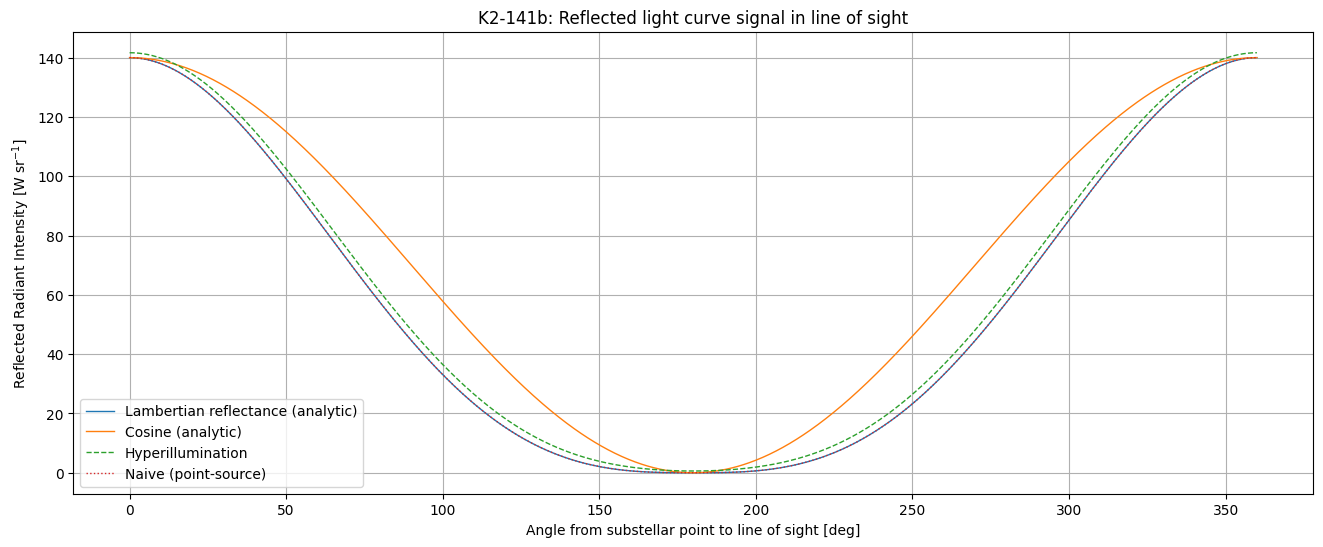

In [4]:
epsilon = np.linspace(0, 360, 1000)

L_kopal = reflected_lightcurve(np.radians(epsilon), K2_141b, insolation_model="kopal", unit="radiant intensity", A=A)
L_naive = reflected_lightcurve(np.radians(epsilon), K2_141b, insolation_model="naive", unit="radiant intensity", A=A)
L_cos = (np.cos(np.radians(epsilon))+1)/2*np.max(L_naive)
L_lambertian = lambertian_reflectance(np.radians(epsilon), K2_141b, unit="radiant intensity", A=A)

plt.figure(figsize=(16, 6))
plt.plot(epsilon, L_lambertian, linewidth=1, label="Lambertian reflectance (analytic)")
plt.plot(epsilon, L_cos, linewidth=1, label="Cosine (analytic)")
plt.plot(epsilon, L_kopal, linewidth=1, linestyle="--", label="Hyperillumination")
plt.plot(epsilon, L_naive, linewidth=1, linestyle=":", label="Naive (point-source)")

plt.xlabel("Angle from substellar point to line of sight [deg]")
plt.ylabel(r"Reflected Radiant Intensity [W sr$^{-1}$]")
plt.title("K2-141b: Reflected light curve signal in line of sight")
plt.legend()
plt.grid()

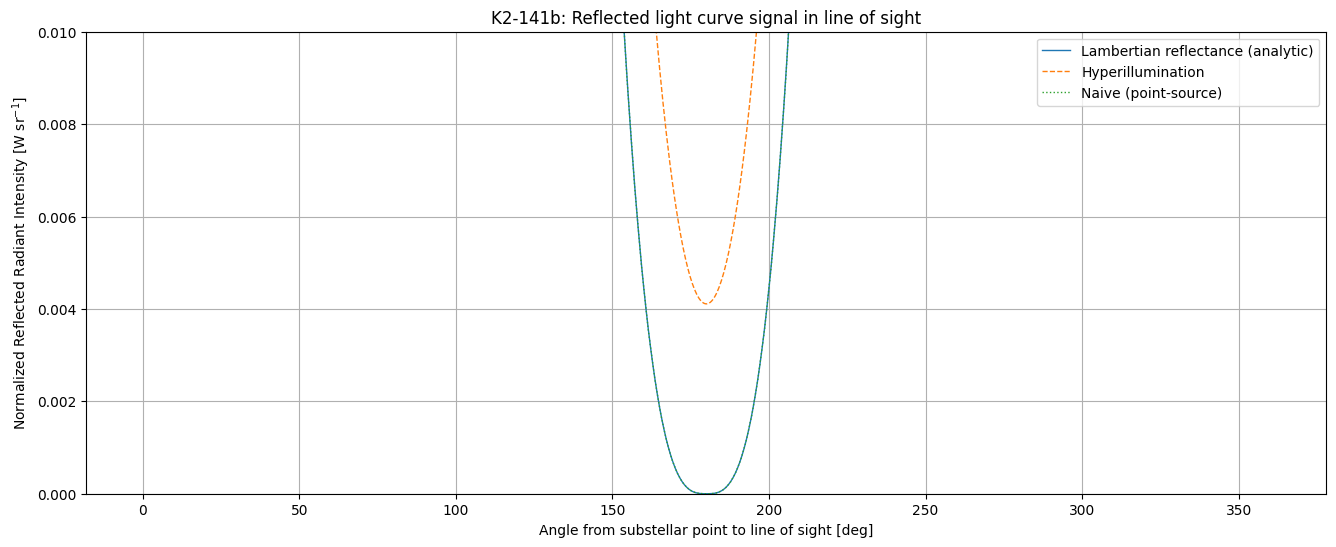

In [5]:
amp = np.max(L_lambertian)
plt.figure(figsize=(16, 6))
plt.plot(epsilon, L_lambertian/amp, linewidth=1, label="Lambertian reflectance (analytic)")
#plt.plot(epsilon, L_cos/amp, linewidth=1, label="Cosine (analytic)")
plt.plot(epsilon, L_kopal/amp, linewidth=1, linestyle="--", label="Hyperillumination")
plt.plot(epsilon, L_naive/amp, linewidth=1, linestyle=":", label="Naive (point-source)")

plt.xlabel("Angle from substellar point to line of sight [deg]")
plt.ylabel(r"Normalized Reflected Radiant Intensity [W sr$^{-1}$]")
plt.title("K2-141b: Reflected light curve signal in line of sight")
plt.legend()
plt.ylim(0., 0.01)
plt.grid()

### Normalized Lightcurve Fp/Fs

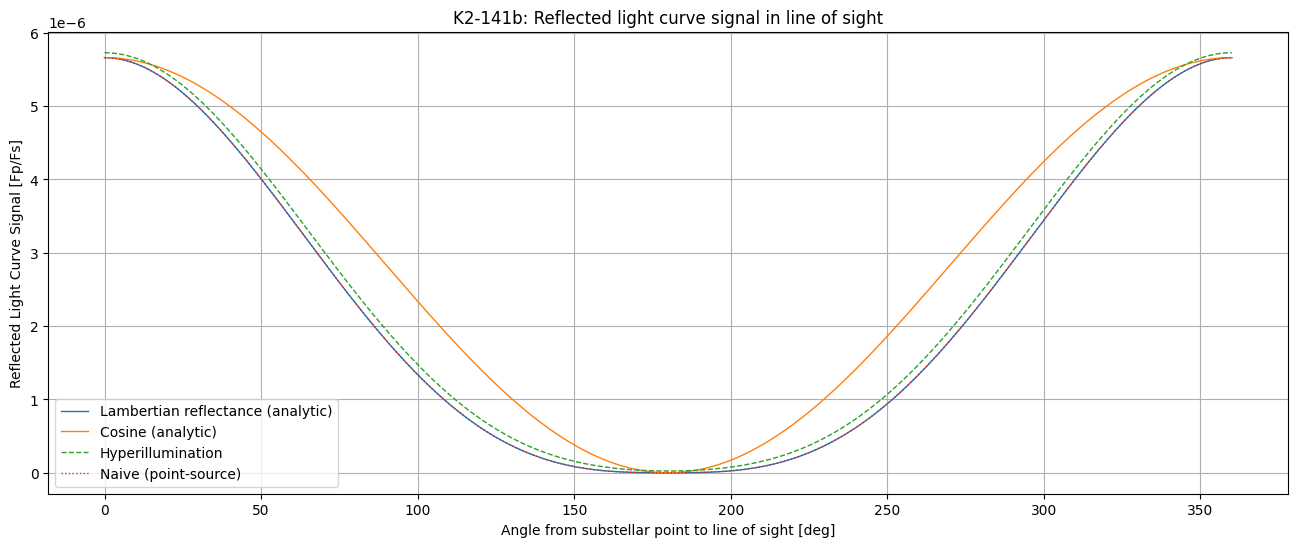

In [6]:
epsilon = np.linspace(0, 360, 1000)

L_kopal = reflected_lightcurve(np.radians(epsilon), K2_141b, insolation_model="kopal", unit="normalized", A=A)
L_naive = reflected_lightcurve(np.radians(epsilon), K2_141b, insolation_model="naive", unit="normalized", A=A)
L_cos = (np.cos(np.radians(epsilon))+1)/2*np.max(L_naive)
L_lambertian = lambertian_reflectance(np.radians(epsilon), K2_141b, unit="normalized", A=A)

plt.figure(figsize=(16, 6))
plt.plot(epsilon, L_lambertian, linewidth=1, label="Lambertian reflectance (analytic)")
plt.plot(epsilon, L_cos, linewidth=1, label="Cosine (analytic)")
plt.plot(epsilon, L_kopal, linewidth=1, linestyle="--", label="Hyperillumination")
plt.plot(epsilon, L_naive, linewidth=1, linestyle=":", label="Naive (point-source)")

plt.xlabel("Angle from substellar point to line of sight [deg]")
plt.ylabel(r"Reflected Light Curve Signal [Fp/Fs]")
plt.title("K2-141b: Reflected light curve signal in line of sight")
plt.legend()
plt.grid()

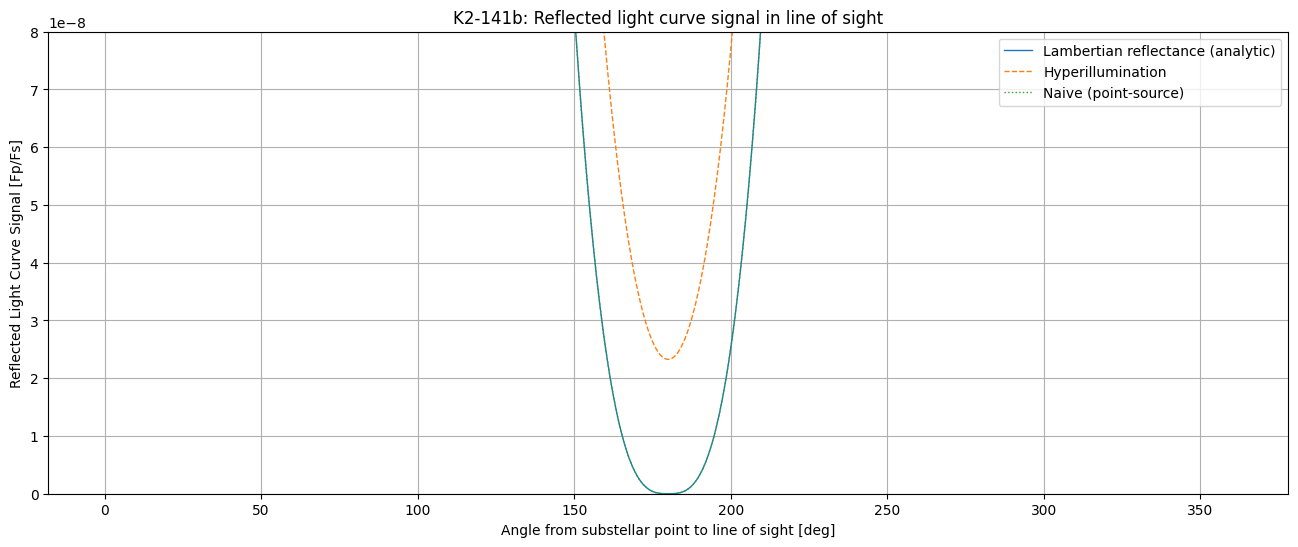

In [7]:
plt.figure(figsize=(16, 6))
plt.plot(epsilon, L_lambertian, linewidth=1, label="Lambertian reflectance (analytic)")
plt.plot(epsilon, L_kopal, linewidth=1, linestyle="--", label="Hyperillumination")
plt.plot(epsilon, L_naive, linewidth=1, linestyle=":", label="Naive (point-source)")

plt.xlabel("Angle from substellar point to line of sight [deg]")
plt.ylabel(r"Reflected Light Curve Signal [Fp/Fs]")
plt.title("K2-141b: Reflected light curve signal in line of sight")
plt.legend()
plt.ylim(0., 0.8e-7)
plt.grid()

## Reflected Phase Curve

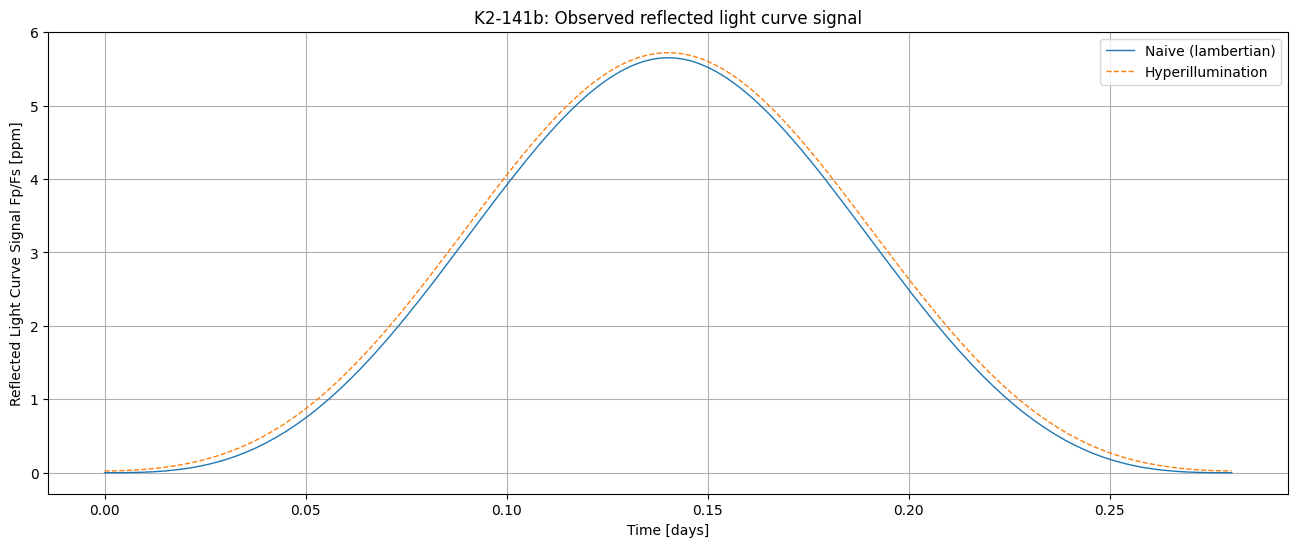

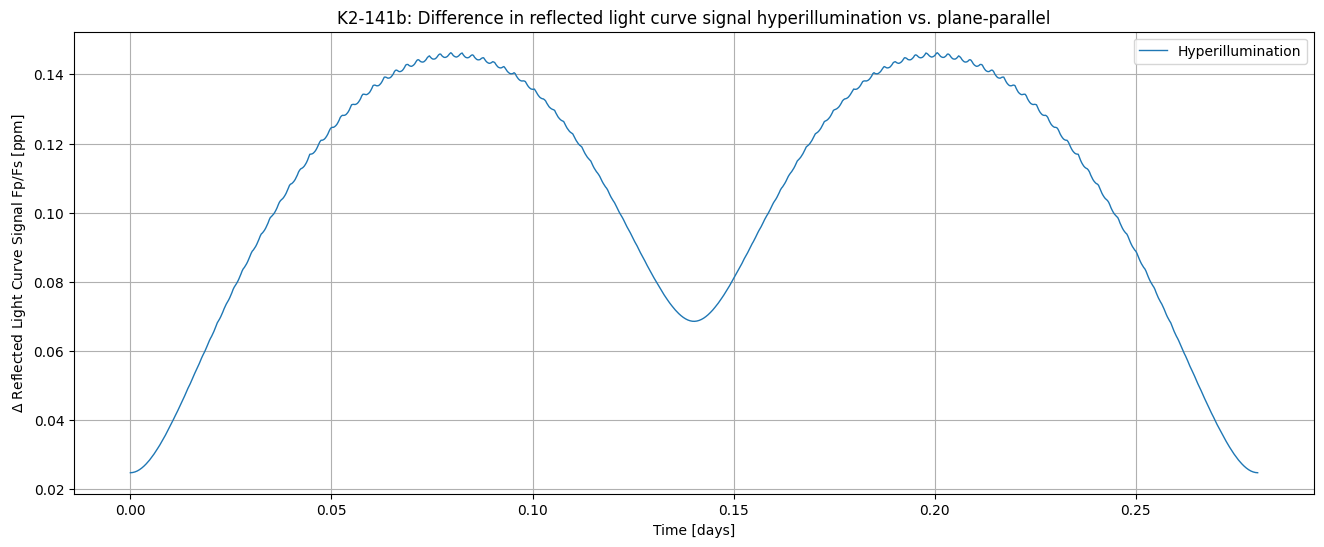

In [8]:
t = np.linspace(0, period, 1000)

orbital_ref_lightcurve_kopal = orbital_reflected_lightcurve(t, K2_141b, A=A)
orbital_ref_lightcurve_naive = orbital_reflected_lightcurve(t, K2_141b, insolation_model="naive", A=A)

plt.figure(figsize=(16, 6))
plt.plot(t, orbital_ref_lightcurve_naive*1e6, linewidth=1, label= "Naive (lambertian)")
plt.plot(t, orbital_ref_lightcurve_kopal*1e6, linewidth=1, linestyle="--", label="Hyperillumination")

plt.xlabel("Time [days]")
plt.ylabel(r"Reflected Light Curve Signal Fp/Fs [ppm]")
plt.title("K2-141b: Observed reflected light curve signal")
plt.legend()
#plt.ylim(0., 0.8e-7)
plt.grid()

plt.figure(figsize=(16, 6))
plt.plot(t, (orbital_ref_lightcurve_kopal-orbital_ref_lightcurve_naive)*1e6, linewidth=1, label="Hyperillumination")
plt.xlabel("Time [days]")
plt.ylabel(f"$\Delta$ Reflected Light Curve Signal Fp/Fs [ppm]")
plt.title("K2-141b: Difference in reflected light curve signal hyperillumination vs. plane-parallel")
plt.legend()
#plt.ylim(0., 0.8e-7)
plt.grid()

Wiggles are a numerical artefact in naive light curve signal caused by truncation at 90° (Gauss-Legendre converges exponentially only for smooth integrands). Can be fixed by setting n_phi = 320.

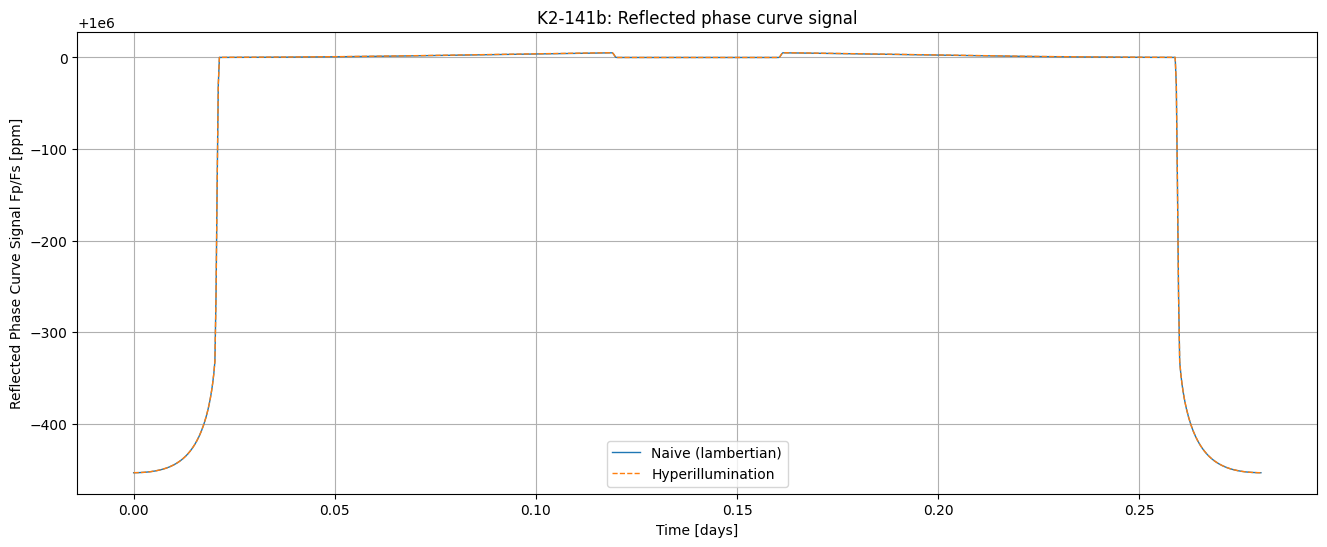

Occultation depth with Hyperillumination: 5.7 ppm   (measured: fp = 142 ppm at 4.5 um)
Occultation depth without Hyperillumination: 5.7 ppm   (measured: fp = 142 ppm at 4.5 um)


In [9]:
t_kopal, ref_phasecurve_kopal, ref_fp_kopal = reflected_PhaseCurve(K2_141b, u=u, A=A)
t_naive, ref_phasecurve_naive, ref_fp_naive = reflected_PhaseCurve(K2_141b, u=u, A=A, insolation_model="naive")

plt.figure(figsize=(16, 6))
plt.plot(t_naive, ref_phasecurve_naive*1e6, linewidth=1, label="Naive (lambertian)")
plt.plot(t_kopal, ref_phasecurve_kopal*1e6, linewidth=1, linestyle="--", label="Hyperillumination")

plt.xlabel("Time [days]")
plt.ylabel(r"Reflected Phase Curve Signal Fp/Fs [ppm]")
plt.title("K2-141b: Reflected phase curve signal")
plt.legend()
plt.grid()
plt.show()

print(f"Occultation depth with Hyperillumination: {ref_fp_kopal:.1f} ppm   (measured: fp = {fp*1e6:.0f} ppm at 4.5 um)")
print(f"Occultation depth without Hyperillumination: {ref_fp_naive:.1f} ppm   (measured: fp = {fp*1e6:.0f} ppm at 4.5 um)")

## Consistency Check - Comparison with Spiderman's Lambertian Model

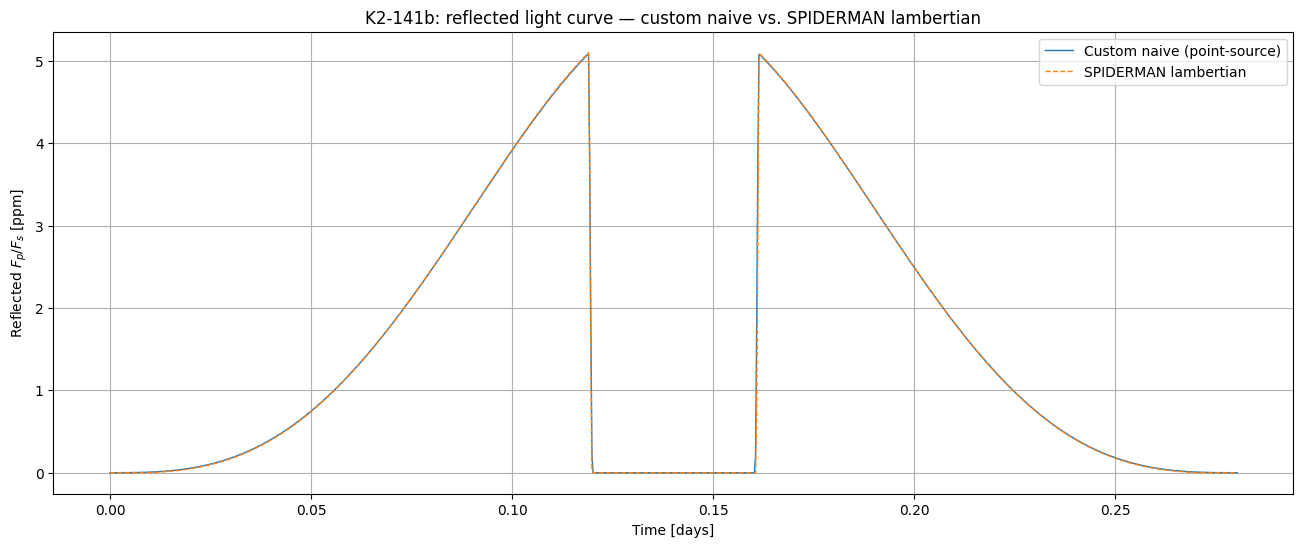

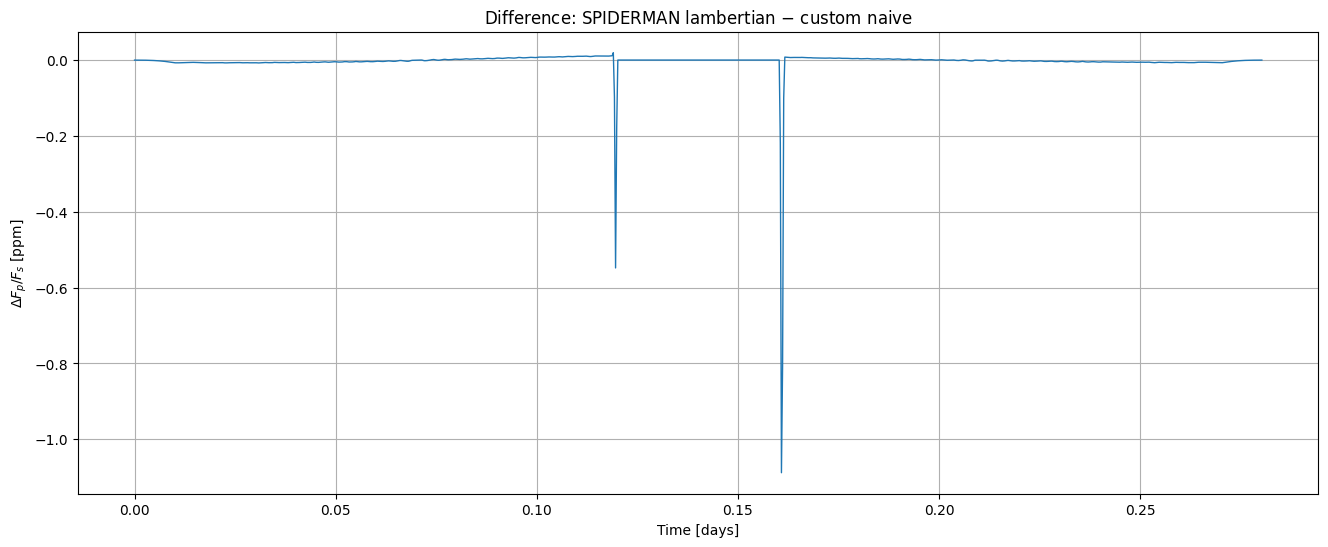

In [10]:
# As expected the Spiderman Lambert model also does not require a wavelength range
sp_lambert = sp.ModelParams(brightness_model="lambertian", stellar_model="blackbody")
sp_lambert.n_layers = 20
sp_lambert.t0, sp_lambert.per = 0., period
sp_lambert.a_abs = a * rs * 6.957e8 / 1.495978707e11    # semi-major axis [AU]
sp_lambert.inc, sp_lambert.ecc, sp_lambert.w = incl, ecc, w
sp_lambert.rp, sp_lambert.a = rp, a
sp_lambert.p_u1 = sp_lambert.p_u2 = 0.
sp_lambert.eclipse = True
sp_lambert.albedo  = 2/3 * A  # SPIDERMAN albedo ≈ geometric A_g = 2/3·A

t_naive, ref_phasecurve_naive, ref_fp_naive = reflected_PhaseCurve(K2_141b, u=u, A=A, insolation_model="naive", include_transit=False)

sp_lambert = sp_lambert.lightcurve(t_naive) - 1.

plt.figure(figsize=(16, 6))
plt.plot(t_naive, ref_phasecurve_naive*1e6,  lw=1, label="Custom naive (point-source)")
plt.plot(t_naive, sp_lambert*1e6, lw=1, ls="--", label="SPIDERMAN lambertian")
plt.xlabel("Time [days]"); plt.ylabel(r"Reflected $F_p/F_s$ [ppm]")
plt.title("K2-141b: reflected light curve — custom naive vs. SPIDERMAN lambertian")
plt.legend(); plt.grid(); plt.show()

plt.figure(figsize=(16, 6))
plt.plot(t_naive, (sp_lambert - ref_phasecurve_naive)*1e6, lw=1)
plt.xlabel("Time [days]"); plt.ylabel(r"$\Delta F_p/F_s$ [ppm]")
plt.title("Difference: SPIDERMAN lambertian $-$ custom naive"); plt.grid(); plt.show()